# Assignment 7 - Data Analysis with NumPy, Pandas and Seaborn
**Jasroop Singh Sachdeva**
Roll Number: 1024170090

Plots are shown below each cell and also saved as images in the `Assignment_7_plots` folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Q.1 E-commerce Sales Data Analysis

## Part I: Randomized Sales Data Generation (NumPy)

### 1. Initialize random seed
Using my roll number as the seed so the data is unique and the same every time the notebook is run.

In [2]:
roll_no = 1024170090
np.random.seed(roll_no)

### 2. Generate sales data
12 months x 4 categories, values between 1000 and 5000 units. `randint`'s upper limit is exclusive so 5001 is used to include 5000.

In [3]:
sales_data = np.random.randint(1000, 5001, size=(12, 4))
print(sales_data)
print("Shape:", sales_data.shape)

[[3592 2068 2471 2200]
 [1836 2678 2596 3906]
 [1812 1267 2366 2652]
 [3028 3446 4206 3033]
 [4824 4521 3061 2005]
 [4071 2942 3131 2770]
 [3324 3203 1417 3624]
 [3062 4016 3196 3958]
 [1321 3144 4513 2225]
 [3976 1686 3873 2388]
 [1749 2005 4249 4739]
 [4726 4074 1435 1489]]
Shape: (12, 4)


### 3. Convert to DataFrame
Columns are the product categories and the index is the month (Jan to Dec).

In [4]:
categories = ["Electronics", "Clothing", "Home & Kitchen", "Sports"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

df = pd.DataFrame(sales_data, columns=categories, index=months)
print(df)

     Electronics  Clothing  Home & Kitchen  Sports
Jan         3592      2068            2471    2200
Feb         1836      2678            2596    3906
Mar         1812      1267            2366    2652
Apr         3028      3446            4206    3033
May         4824      4521            3061    2005
Jun         4071      2942            3131    2770
Jul         3324      3203            1417    3624
Aug         3062      4016            3196    3958
Sep         1321      3144            4513    2225
Oct         3976      1686            3873    2388
Nov         1749      2005            4249    4739
Dec         4726      4074            1435    1489


## Part II: Data Manipulation and Analysis (Pandas)

### 1. First 5 rows and summary statistics

In [5]:
print(df.head())

     Electronics  Clothing  Home & Kitchen  Sports
Jan         3592      2068            2471    2200
Feb         1836      2678            2596    3906
Mar         1812      1267            2366    2652
Apr         3028      3446            4206    3033
May         4824      4521            3061    2005


In [6]:
print(df.describe())

       Electronics     Clothing  Home & Kitchen       Sports
count    12.000000    12.000000       12.000000    12.000000
mean   3110.083333  2920.833333     3042.833333  2915.750000
std    1201.158491  1017.144294     1040.242265   959.655632
min    1321.000000  1267.000000     1417.000000  1489.000000
25%    1830.000000  2052.250000     2444.750000  2218.750000
50%    3193.000000  3043.000000     3096.000000  2711.000000
75%    3999.750000  3588.500000     3956.250000  3694.500000
max    4824.000000  4521.000000     4513.000000  4739.000000


### 2. Total sales per category and per month

In [7]:
total_per_category = df.sum(axis=0)
print("Total sales per category:")
print(total_per_category)

Total sales per category:
Electronics       37321
Clothing          35050
Home & Kitchen    36514
Sports            34989
dtype: int64


In [8]:
total_per_month = df.sum(axis=1)
print("Total sales per month:")
print(total_per_month)

Total sales per month:
Jan    10331
Feb    11016
Mar     8097
Apr    13713
May    14411
Jun    12914
Jul    11568
Aug    14232
Sep    11203
Oct    11923
Nov    12742
Dec    11724
dtype: int64


### 3. Average sales growth between consecutive months
`pct_change()` gives the % change from the previous month for each category, then I take the mean of those. The first row is NaN (no previous month) and is skipped by `mean()`.
I also printed the average change in units using `diff()`.

In [9]:
avg_growth_pct = df.pct_change().mean() * 100
avg_growth_units = df.diff().mean()

growth = pd.DataFrame({
    "Avg Growth (%)": avg_growth_pct.round(2),
    "Avg Change (units)": avg_growth_units.round(2)
})
print(growth)

                Avg Growth (%)  Avg Change (units)
Electronics              26.61              103.09
Clothing                 21.21              182.36
Home & Kitchen            8.21              -94.18
Sports                    8.87              -64.64


### 4. Add Total Sales and Growth Rate columns
- **Total Sales** = sum of the 4 categories for that month
- **Growth Rate** = % change in Total Sales from the previous month (Jan is NaN)

In [10]:
df["Total Sales"] = df[categories].sum(axis=1)
df["Growth Rate"] = (df["Total Sales"].pct_change() * 100).round(2)
print(df)

     Electronics  Clothing  Home & Kitchen  Sports  Total Sales  Growth Rate
Jan         3592      2068            2471    2200        10331          NaN
Feb         1836      2678            2596    3906        11016         6.63
Mar         1812      1267            2366    2652         8097       -26.50
Apr         3028      3446            4206    3033        13713        69.36
May         4824      4521            3061    2005        14411         5.09
Jun         4071      2942            3131    2770        12914       -10.39
Jul         3324      3203            1417    3624        11568       -10.42
Aug         3062      4016            3196    3958        14232        23.03
Sep         1321      3144            4513    2225        11203       -21.28
Oct         3976      1686            3873    2388        11923         6.43
Nov         1749      2005            4249    4739        12742         6.87
Dec         4726      4074            1435    1489        11724        -7.99

### 5. Apply discount based on roll number
Even roll number -> 10% discount on Electronics, odd -> 15% discount on Clothing.
After the discount, Total Sales and Growth Rate are recalculated so they match the new values.

In [11]:
if roll_no % 2 == 0:
    print(f"Roll number {roll_no} is even -> 10% discount on Electronics")
    df["Electronics"] = df["Electronics"] * 0.90
else:
    print(f"Roll number {roll_no} is odd -> 15% discount on Clothing")
    df["Clothing"] = df["Clothing"] * 0.85

df["Total Sales"] = df[categories].sum(axis=1)
df["Growth Rate"] = (df["Total Sales"].pct_change() * 100).round(2)
print(df.round(2))

Roll number 1024170090 is even -> 10% discount on Electronics
     Electronics  Clothing  Home & Kitchen  Sports  Total Sales  Growth Rate
Jan       3232.8      2068            2471    2200       9971.8          NaN
Feb       1652.4      2678            2596    3906      10832.4         8.63
Mar       1630.8      1267            2366    2652       7915.8       -26.92
Apr       2725.2      3446            4206    3033      13410.2        69.41
May       4341.6      4521            3061    2005      13928.6         3.87
Jun       3663.9      2942            3131    2770      12506.9       -10.21
Jul       2991.6      3203            1417    3624      11235.6       -10.16
Aug       2755.8      4016            3196    3958      13925.8        23.94
Sep       1188.9      3144            4513    2225      11070.9       -20.50
Oct       3578.4      1686            3873    2388      11525.4         4.11
Nov       1574.1      2005            4249    4739      12567.1         9.04
Dec       4253

## Part III: Visualizations (Matplotlib and Seaborn)

### 1. Monthly sales trend for each category (line plots)

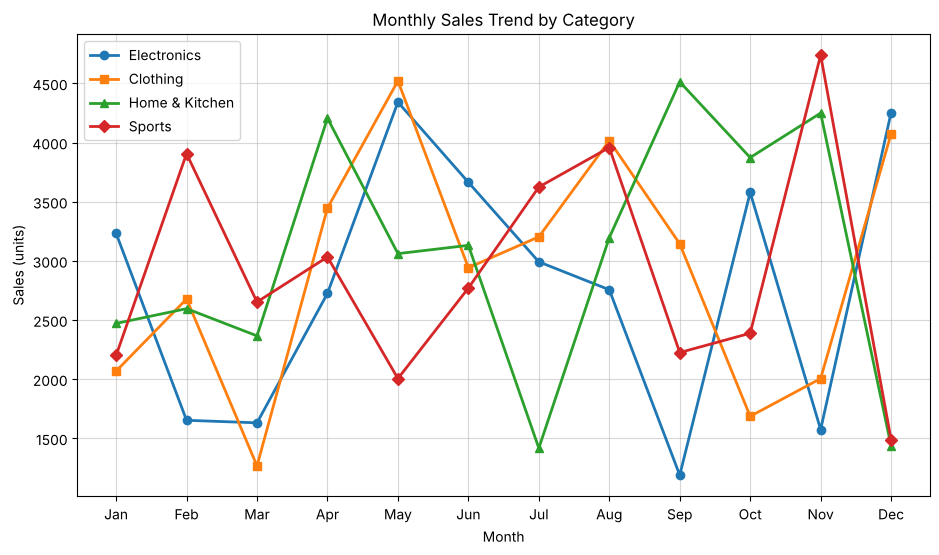

In [12]:
plt.figure(figsize=(11, 6))
markers = ["o", "s", "^", "D"]
for cat, m in zip(categories, markers):
    plt.plot(df.index, df[cat], marker=m, linewidth=2, label=cat)

plt.title("Monthly Sales Trend by Category")
plt.xlabel("Month")
plt.ylabel("Sales (units)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig("Assignment_7_plots/monthly_sales_trend.png", dpi=120, bbox_inches="tight")
plt.show()

Same data with a separate line plot for each category, makes the individual trends easier to see.

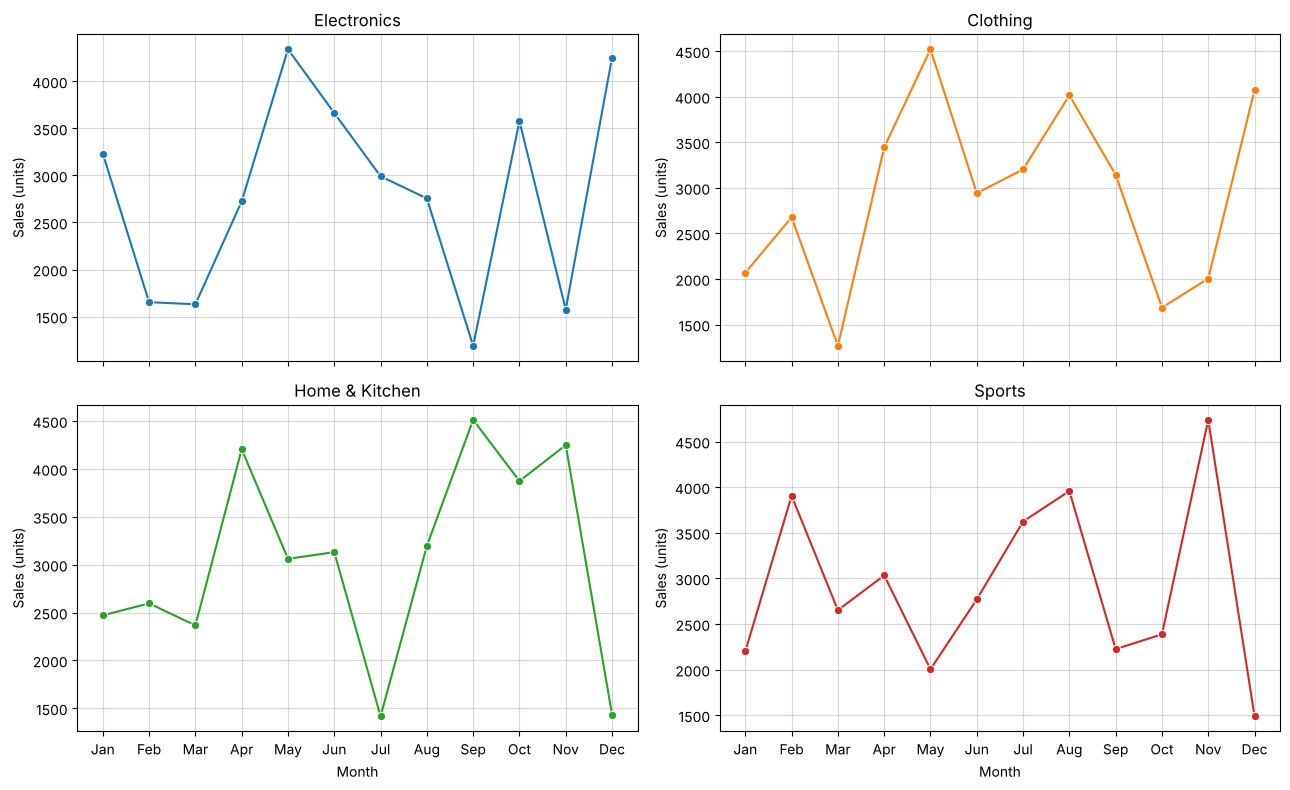

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

for ax, cat, c in zip(axes.flatten(), categories, colors):
    sns.lineplot(x=df.index, y=df[cat], ax=ax, marker="o", color=c)
    ax.set_title(cat)
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales (units)")
    ax.grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("Assignment_7_plots/category_trends.png", dpi=120, bbox_inches="tight")
plt.show()

### 2. Box plots - sales distribution for each category

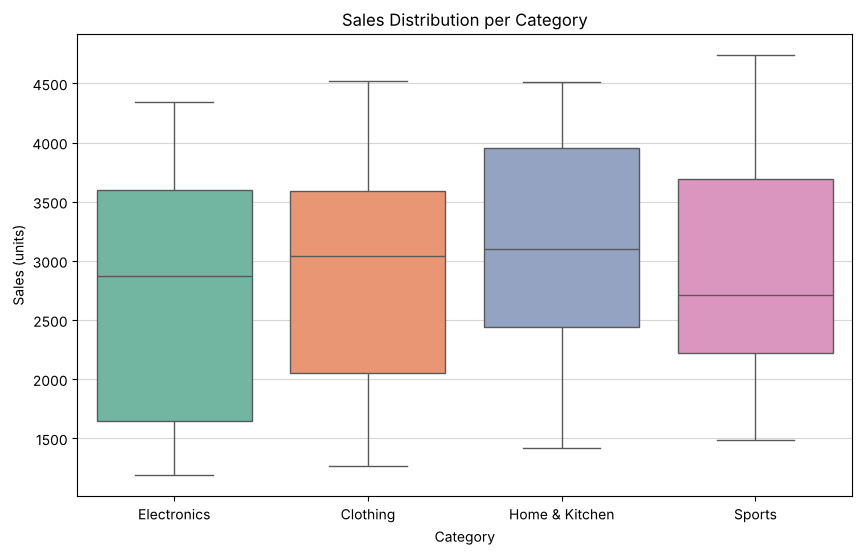

In [14]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[categories], palette="Set2")
plt.title("Sales Distribution per Category")
plt.xlabel("Category")
plt.ylabel("Sales (units)")
plt.grid(axis="y", alpha=0.5)
plt.savefig("Assignment_7_plots/sales_boxplot.png", dpi=120, bbox_inches="tight")
plt.show()

---
## Q.2 Operations on a 2D array

In [15]:
array = np.array([[1, -2, 3],
                  [-4, 5, -6]])
print(array)

[[ 1 -2  3]
 [-4  5 -6]]


**i. Element-wise absolute value**

In [16]:
print(np.abs(array))

[[1 2 3]
 [4 5 6]]


**ii. 25th, 50th and 75th percentile** - for the flattened array, each column (axis=0) and each row (axis=1)

In [17]:
q = [25, 50, 75]

print("Flattened array:", array.flatten())
print("Percentiles (flattened):", np.percentile(array, q))

print("\nPercentiles for each column (rows = 25th, 50th, 75th):")
print(np.percentile(array, q, axis=0))

print("\nPercentiles for each row (rows = 25th, 50th, 75th):")
print(np.percentile(array, q, axis=1))

Flattened array: [ 1 -2  3 -4  5 -6]
Percentiles (flattened): [-3.5 -0.5  2.5]

Percentiles for each column (rows = 25th, 50th, 75th):
[[-2.75 -0.25 -3.75]
 [-1.5   1.5  -1.5 ]
 [-0.25  3.25  0.75]]

Percentiles for each row (rows = 25th, 50th, 75th):
[[-0.5 -5. ]
 [ 1.  -4. ]
 [ 2.   0.5]]


**iii. Mean, median and standard deviation** - flattened, each column and each row

In [18]:
print("Flattened -> Mean:", np.mean(array), " Median:", np.median(array), " Std:", round(np.std(array), 4))

print("\nColumn-wise")
print("Mean  :", np.mean(array, axis=0))
print("Median:", np.median(array, axis=0))
print("Std   :", np.std(array, axis=0))

print("\nRow-wise")
print("Mean  :", np.mean(array, axis=1))
print("Median:", np.median(array, axis=1))
print("Std   :", np.round(np.std(array, axis=1), 4))

Flattened -> Mean: -0.5  Median: -0.5  Std: 3.8622

Column-wise
Mean  : [-1.5  1.5 -1.5]
Median: [-1.5  1.5 -1.5]
Std   : [2.5 3.5 4.5]

Row-wise
Mean  : [ 0.66666667 -1.66666667]
Median: [ 1. -4.]
Std   : [2.0548 4.7842]


---
## Q.3 Floor, ceiling, truncate and round

In [19]:
a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])

print("Array    :", a)
print("Floor    :", np.floor(a))
print("Ceil     :", np.ceil(a))
print("Truncated:", np.trunc(a))
print("Rounded  :", np.round(a))

Array    : [-1.8 -1.6 -0.5  0.5  1.6  1.8  3. ]
Floor    : [-2. -2. -1.  0.  1.  1.  3.]
Ceil     : [-1. -1. -0.  1.  2.  2.  3.]
Truncated: [-1. -1. -0.  0.  1.  1.  3.]
Rounded  : [-2. -2. -0.  0.  2.  2.  3.]


Note: `np.round` rounds .5 values to the nearest **even** number, which is why -0.5 and 0.5 both become 0 (shown as -0. and 0.).

---
## Q.4 Swap two elements in a list using a temporary variable

In [20]:
def swap_list(lst, i, j):
    temp = lst[i]
    lst[i] = lst[j]
    lst[j] = temp
    return lst

nums = [10, 20, 30, 40, 50]
print("Before swap:", nums)
swap_list(nums, 1, 3)
print("After swapping index 1 and 3:", nums)

Before swap: [10, 20, 30, 40, 50]
After swapping index 1 and 3: [10, 40, 30, 20, 50]


---
## Q.5 Swap two elements in a set by converting it to a list
Sets are unordered and don't support indexing, so the set is first converted to a list, the swap is done on the list.

In [21]:
my_set = {15, 25, 35, 45, 55}
print("Original set:", my_set)

my_list = list(my_set)
print("Set as list :", my_list)

i, j = 0, 2
my_list[i], my_list[j] = my_list[j], my_list[i]
print(f"After swapping positions {i} and {j}:", my_list)

Original set: {35, 55, 25, 45, 15}
Set as list : [35, 55, 25, 45, 15]
After swapping positions 0 and 2: [25, 55, 35, 45, 15]


If the list is converted back to a set the order isn't kept, since sets have no fixed positions, so the swapped result is kept as a list.